# TP2 - Parte 1: dataset y preprocesamiento

## Equipo
- Alumno 1 : Alejandro Armas
- Alumno 2 : Gabriel Soda

In [9]:
# Configuración global: imports, paths, semilla y paleta de colores fija del proyecto.
import warnings
from pathlib import Path

import random
import base64
import hashlib
import shutil
import sys

import albumentations as A
import altair as alt
import cv2
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import display
from PIL import Image, UnidentifiedImageError

alt.data_transformers.disable_max_rows()

ROOT = Path.cwd()
DATASET_DIR = ROOT / "data" / "dataset"
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEED = 42
SPLITS_DIR = ROOT / "splits"

# `src/lib` es el código compartido con la app (pipeline de imagen y augmentation).
SRC_DIR = ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

COLORS = {
    "primary": "#4c78a8",
    "secondary": "#f58518",
    "negative": "#e45756",
    "positive": "#54a24b",
    "neutral": "#72b7b2",
    "gray": "#b3b3b3",
    "warning": "#f2cf4a",
}
CATEGORICAL_COLORS = [
    COLORS["primary"],
    COLORS["secondary"],
    COLORS["negative"],
    COLORS["positive"],
    COLORS["neutral"],
    COLORS["warning"],
    "#9d7660",
    "#b279a2",
    "#54a24b",
    "#ff9da6",
    "#72b7b2",
    "#f2cf4a",
    "#4c78a8",
    "#e45756",
    "#f58518",
    "#9d7660",
]


def inline(df: pl.DataFrame) -> alt.InlineData:
    """Convierte un DataFrame de Polars a InlineData para Altair."""
    return alt.InlineData(values=df.to_dicts())


# Mapeo para mostrar columnas en español; los nombres internos del código siguen en inglés.
NOMBRES_ES = {
    "split": "partición",
    "breed": "raza",
    "path": "ruta",
    "filename": "archivo",
    "suffix": "extensión",
    "images": "imágenes",
    "mean": "media",
    "median": "mediana",
    "min": "mín",
    "max": "máx",
    "std": "desvío",
    "cv": "coef. variación",
    "format": "formato",
    "mode": "modo",
    "width": "ancho",
    "height": "alto",
    "aspect_ratio": "relación aspecto",
    "pixels": "píxeles",
    "brightness": "brillo",
    "contrast": "contraste",
    "laplacian_var": "var. Laplaciano",
    "readable": "legible",
    "error": "error",
    "quality_rule": "regla",
}


def mostrar(df: pl.DataFrame) -> None:
    """Muestra un DataFrame con los nombres de columnas en español."""
    renombrar = {k: v for k, v in NOMBRES_ES.items() if k in df.columns}
    display(df.rename(renombrar))

In [10]:
# Verificamos si el dataset ya está descargado y damos la instrucción exacta si falta.
splits_available = [
    split for split in ("train", "valid", "test") if (DATASET_DIR / split).is_dir()
]
HAS_DATASET = len(splits_available) > 0

if HAS_DATASET:
    print(f"Dataset encontrado en {DATASET_DIR} (splits: {splits_available})")
else:
    print(f"No se encontró el dataset en {DATASET_DIR}.")
    print("Descargalo con: python scripts/download_dataset.py")
    print("O descomprimí manualmente train/, valid/ y test/ dentro de data/dataset/.")

Dataset encontrado en c:\Users\Gabi\Proyectos\tuia-dog-recognition-app\data\dataset (splits: ['train', 'valid', 'test'])


## 3.1 Descripción del dataset

Usamos el **70 Dog Breeds Image Dataset** ([Kaggle](https://www.kaggle.com/datasets/gpiosenka/70-dog-breedsimage-data-set)),
que ya viene particionado en `train/`, `valid/` y `test/` con una carpeta por raza.
La licencia publicada en Kaggle es **CC0: Public Domain**; igualmente conviene revisar
la página actual del dataset antes de cualquier uso comercial, porque los derechos de
las imágenes individuales pueden tener otra procedencia.

**Encabezado esperado.** Las imágenes del dataset suelen ser recortes centrados en un
único perro, con fondo variable (césped, interior, personas, otros perros) y resolución
chica a media. Eso contrasta con lo que va a recibir el clasificador en la **Etapa 3**:
recortes de YOLO, con otro encuadre, escala y, muchas veces, un perro que ocupa menos
la imagen. Ese cambio de dominio se mide con el conjunto independiente (3.4).

**Limitaciones que asumimos desde el arranque:** razas visualmente muy parecidas entre
sí (husky/malamute, etc.), sesgo de imágenes de origen web, ausencia de perros mestizos,
etiquetas que pueden contener errores y poca variedad de contextos (mucho retrato y poco
perro lejano o en movimiento).

In [11]:
# Inventario: recorremos las carpetas sin cargar píxeles, solo path + split + raza.
# Cada fila es una imagen candidata del dataset original (antes de cualquier filtro).
def scan_dataset(dataset_dir: Path) -> pl.DataFrame:
    """Recorre train/valid/test y devuelve una fila por imagen encontrada."""
    records = []
    for split in ("train", "valid", "test"):
        split_dir = dataset_dir / split
        if not split_dir.is_dir():
            continue
        for image_path in sorted(split_dir.rglob("*")):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_SUFFIXES:
                records.append(
                    {
                        "split": split,
                        "breed": image_path.parent.name,
                        "path": image_path.relative_to(dataset_dir).as_posix(),
                        "filename": image_path.name,
                        "suffix": image_path.suffix.lower(),
                    }
                )

    return pl.from_dicts(
        records,
        schema={
            "split": pl.String,
            "breed": pl.String,
            "path": pl.String,
            "filename": pl.String,
            "suffix": pl.String,
        },
    )


inventory = scan_dataset(DATASET_DIR).with_columns(
    pl.col("breed").str.replace_all(r"\s+", " ").str.strip_chars()
)
print(f"Imágenes encontradas: {inventory.height}")
mostrar(inventory.head(5))

Imágenes encontradas: 9346


partición,raza,ruta,archivo,extensión
str,str,str,str,str
"""train""","""Afghan""","""train/Afghan/001.jpg""","""001.jpg""",""".jpg"""
"""train""","""Afghan""","""train/Afghan/002.jpg""","""002.jpg""",""".jpg"""
"""train""","""Afghan""","""train/Afghan/003.jpg""","""003.jpg""",""".jpg"""
"""train""","""Afghan""","""train/Afghan/004.jpg""","""004.jpg""",""".jpg"""
"""train""","""Afghan""","""train/Afghan/005.jpg""","""005.jpg""",""".jpg"""


In [12]:
# Conteo de razas e imágenes por split, para ver de entrada si la partición es la esperada.
breed_split_counts = (
    inventory.group_by(["split", "breed"]).len().rename({"len": "images"})
)

split_summary = breed_split_counts.group_by("split").agg(
    pl.col("images").sum().alias("cant. imágenes"),
    pl.col("breed").n_unique().alias("razas"),
)

mostrar(split_summary)

partición,cant. imágenes,razas
str,u32,u32
"""train""",7946,70
"""test""",700,70
"""valid""",700,70


## 3.2 Análisis exploratorio (EDA)

El objetivo del EDA es entender **desbalance de clases**, **resoluciones/formato** y
**variabilidad fotométrica** antes de filtrar. Mantenemos la regla del proyecto: Polars
para agregar y Altair para graficar, con la paleta fija definida arriba.

In [13]:
# Antes de decidir qué graficar, verificamos cuántas imágenes por raza hay en cada split.
# Si valid y test resultan uniformes, el desbalance solo puede estudiarse en train.
split_breed_stats = breed_split_counts.group_by("split").agg(
    pl.col("images").min().alias("mín por raza"),
    pl.col("images").max().alias("máx por raza"),
    pl.col("images").n_unique().alias("valores distintos"),
)
mostrar(split_breed_stats)

partición,mín por raza,máx por raza,valores distintos
str,u32,u32,u32
"""valid""",10,10,1
"""train""",65,198,48
"""test""",10,10,1


`valid` y `test` tienen exactamente **10 imágenes por raza** (mín = máx = 10 y un solo
valor distinto). Con una partición tan uniforme, el histograma de desbalance solo aporta
información en `train`, así que lo graficamos únicamente para ese split.

In [ ]:
# Estadísticas de desbalance de train: media, mediana, mín, máx, desvío y coeficiente de variación.
train_breed_counts = breed_split_counts.filter(pl.col("split") == "train").select(
    ["breed", "images"]
)

train_stats = train_breed_counts.select(
    pl.col("images").mean().round(1).alias("media"),
    pl.col("images").median().alias("mediana"),
    pl.col("images").min().alias("mín"),
    pl.col("images").max().alias("máx"),
    pl.col("images").std().round(1).alias("desvío"),
    (pl.col("images").std() / pl.col("images").mean()).round(2).alias("coef. variación"),
)
mostrar(train_stats)

media,mediana,mín,máx,desvío,coef. variación
f64,f64,u32,u32,f64,f64
113.5,111.5,65,198,24.7,0.22


In [15]:
# Histograma de imágenes por raza para train: muestra cuán balanceadas están las 70 clases.
bin_step = 10
if not train_breed_counts.is_empty():
    hist_chart = (
        alt.Chart(inline(train_breed_counts))
        .mark_bar(opacity=0.75)
        .encode(
            x=alt.X(
                "images:Q",
                bin=alt.Bin(step=bin_step),
                title="Imágenes por raza (train)",
            ),
            y=alt.Y("count():Q", title="Razas"),
            color=alt.value(COLORS["primary"]),
            tooltip=[alt.Tooltip("count():Q", title="Razas")],
        )
        .properties(width=500, height=280, title="Desbalance de train")
    )
    display(hist_chart)
else:
    print("Sin datos para graficar la distribución de train.")

alt.Chart(...)

In [16]:
# Cargamos cada imagen una única vez y guardamos metadatos: tamaño, modo, formato, brillo,
# contraste y varianza del Laplaciano (la usamos después para detectar borrosas).
# `warnings` como error nos permite capturar archivos corruptos que PIL no termina de decodificar.
def compute_image_metadata(inventory: pl.DataFrame, dataset_dir: Path) -> pl.DataFrame:
    """Lee cada imagen y devuelve metadatos fotométricos + de decodificación."""
    records = []
    for row in inventory.iter_rows(named=True):
        path = dataset_dir / row["path"]
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("error")
                with Image.open(path) as image:
                    image.load()
                    width, height = image.size
                    image_format, image_mode = image.format, image.mode
                    gray = np.asarray(image.convert("L"), dtype=np.float32)
                    brightness = float(gray.mean())
                    contrast = float(gray.std())
                    laplacian_var = float(
                        cv2.Laplacian(gray.astype(np.uint8), cv2.CV_64F).var()
                    )

            records.append(
                {
                    **row,
                    "width": width,
                    "height": height,
                    "aspect_ratio": round(width / height, 3),
                    "pixels": width * height,
                    "format": image_format,
                    "mode": image_mode,
                    "brightness": round(brightness, 2),
                    "contrast": round(contrast, 2),
                    "laplacian_var": round(laplacian_var, 2),
                    "readable": True,
                    "error": None,
                }
            )
        except (UnidentifiedImageError, OSError, ValueError, Warning) as error:
            records.append(
                {
                    **row,
                    "width": None,
                    "height": None,
                    "aspect_ratio": None,
                    "pixels": None,
                    "format": None,
                    "mode": None,
                    "brightness": None,
                    "contrast": None,
                    "laplacian_var": None,
                    "readable": False,
                    "error": type(error).__name__,
                }
            )

    return pl.from_dicts(
        records,
        schema={
            "split": pl.String,
            "breed": pl.String,
            "path": pl.String,
            "filename": pl.String,
            "suffix": pl.String,
            "width": pl.Int64,
            "height": pl.Int64,
            "aspect_ratio": pl.Float64,
            "pixels": pl.Int64,
            "format": pl.String,
            "mode": pl.String,
            "brightness": pl.Float64,
            "contrast": pl.Float64,
            "laplacian_var": pl.Float64,
            "readable": pl.Boolean,
            "error": pl.String,
        },
    )


image_meta = compute_image_metadata(inventory, DATASET_DIR)
print(f"Metadatos calculados para {image_meta.height} imágenes")
mostrar(image_meta.sample(5, seed=SEED))

Metadatos calculados para 9346 imágenes


partición,raza,ruta,archivo,extensión,ancho,alto,relación aspecto,píxeles,formato,modo,brillo,contraste,var. Laplaciano,legible,error
str,str,str,str,str,i64,i64,f64,i64,str,str,f64,f64,f64,bool,str
"""train""","""Shih-Tzu""","""train/Shih-Tzu/098.jpg""","""098.jpg""",""".jpg""",224,224,1.0,50176,"""JPEG""","""RGB""",114.78,58.73,4349.56,true,null
"""train""","""Cockapoo""","""train/Cockapoo/074.jpg""","""074.jpg""",""".jpg""",224,224,1.0,50176,"""JPEG""","""RGB""",92.13,41.79,460.21,true,null
"""test""","""Pekinese""","""test/Pekinese/08.jpg""","""08.jpg""",""".jpg""",224,224,1.0,50176,"""JPEG""","""RGB""",122.47,52.69,159.96,true,null
"""train""","""Poodle""","""train/Poodle/064.jpg""","""064.jpg""",""".jpg""",224,224,1.0,50176,"""JPEG""","""RGB""",107.34,39.95,88.48,true,null
"""train""","""Shiba Inu""","""train/Shiba Inu/05.jpg""","""05.jpg""",""".jpg""",224,224,1.0,50176,"""JPEG""","""RGB""",109.75,49.69,2543.27,true,null


In [ ]:
# Formatos/modos y dimensiones: verificamos extensiones y que todo esté en 224×224.
readable = image_meta.filter(pl.col("readable"))
print(f"Legibles: {readable.height} | No legibles: {image_meta.height - readable.height}")

if not readable.is_empty():
    format_counts = (
        readable.group_by(["format", "mode"])
        .len()
        .rename({"len": "imágenes"})
        .sort("imágenes", descending=True)
    )
    mostrar(format_counts)

    dimension_counts = (
        readable.with_columns(
            pl.concat_str(
                pl.col("width").cast(pl.String),
                pl.lit("×"),
                pl.col("height").cast(pl.String),
            ).alias("dimensiones")
        )
        .group_by("dimensiones")
        .len()
        .rename({"len": "imágenes"})
        .sort("imágenes", descending=True)
    )
    mostrar(dimension_counts)
else:
    print("Sin imágenes legibles para resumir formatos/dimensiones.")

Legibles: 9346 | No legibles: 0


formato,modo,imágenes
str,str,u32
"""JPEG""","""RGB""",9346


dimensiones,imágenes
str,u32
"""224×224""",9346


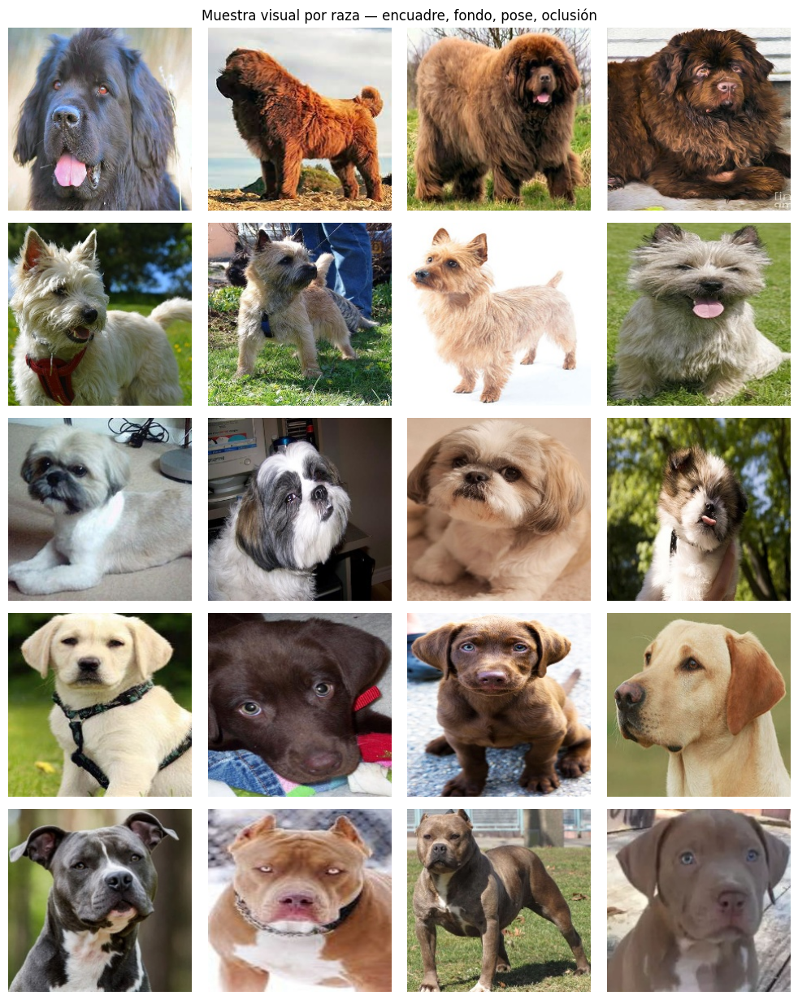

In [ ]:
# Grilla visual de ejemplos por raza: sirve para inspeccionar encuadre, fondo, pose y oclusión.
def show_breed_grid(
    meta: pl.DataFrame,
    dataset_dir: Path,
    breeds: list[str] | None = None,
    n_breeds: int = 5,
    n_samples: int = 4,
    seed: int = SEED,
) -> None:
    """Muestra una grilla de ejemplos por raza (matplotlib, no Altair)."""
    if breeds is None:
        breeds = (
            meta["breed"]
            .unique()
            .sort()
            .sample(n=n_breeds, seed=seed, shuffle=True)
            .to_list()
        )

    fig, axes = plt.subplots(
        len(breeds), n_samples, figsize=(2.5 * n_samples, 2.5 * len(breeds)),
        squeeze=False,
    )
    for i, breed in enumerate(breeds):
        breed_meta = meta.filter(pl.col("breed") == breed)
        paths = (
            breed_meta.sample(n=n_samples, seed=seed)["path"]
            .to_list()
        )
        for j in range(n_samples):
            ax = axes[i, j]
            if j < len(paths):
                with Image.open(dataset_dir / paths[j]) as image:
                    ax.imshow(image.convert("RGB"))
            ax.axis("off")
            if j == 0:
                ax.set_ylabel(breed, fontsize=9, rotation=0, ha="right", va="center")

    fig.suptitle("Muestra visual por raza — encuadre, fondo, pose, oclusión", fontsize=12)
    plt.tight_layout()
    plt.show()


show_breed_grid(image_meta.filter(pl.col("split") == "train"), DATASET_DIR)

alt.Chart(...)
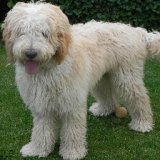
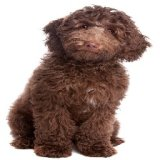
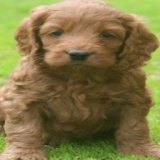
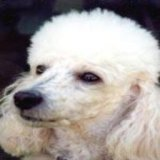
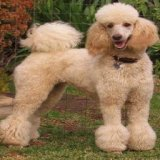
...
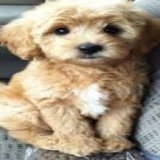
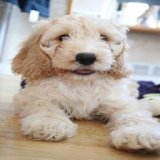
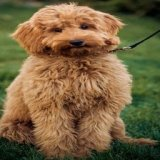
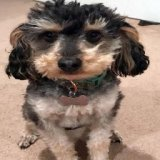
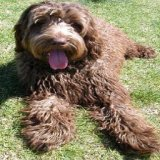

In [ ]:
CONFUSABLE_BREEDS = ["Cockapoo", "Poodle", "Labradoodle"]


def to_image_uri(path: Path, size: int = 160) -> str:
    """Miniatura como data URI JPEG, para que Altair la muestre sin depender de un servidor."""
    image = cv2.imread(str(path))
    if image is None:
        return ""
    image = cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA)
    _, buffer = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, 85])
    return "data:image/jpeg;base64," + base64.b64encode(buffer.tobytes()).decode()


# Muestra una comparación visual de razas fáciles de confundir: imágenes mezcladas (no agrupadas
# por raza) y tooltip con la raza real, para ver cuánto se parecen entre sí.
def show_breed_comparison(
    meta: pl.DataFrame,
    dataset_dir: Path,
    breeds: list[str] = CONFUSABLE_BREEDS,
    n_samples: int = 6,
    columns: int = 6,
    seed: int = SEED,
) -> None:
    """Muestra una grilla Altair con razas parecidas en posiciones aleatorias."""
    readable_meta = meta.filter(pl.col("readable"), pl.col("split") == "train")
    available = [breed for breed in breeds if breed in readable_meta["breed"].to_list()]
    if not available:
        print("No hay imágenes legibles para las razas pedidas.")
        return

    samples = (
        readable_meta.filter(pl.col("breed").is_in(available))
        .sample(fraction=1.0, shuffle=True, seed=seed)  # mezcla todas las imágenes
        .group_by("breed")
        .head(n_samples)                                # n_samples por raza
        .sample(fraction=1.0, shuffle=True, seed=seed)  # mezcla los samples
        .select("path", "breed", "filename")
        .to_dicts()
    )

    rows = len(samples) // columns + (1 if len(samples) % columns else 0)
    images = pl.DataFrame(
        [
            {
                "column": index % columns,
                "row": rows - 1 - index // columns,
                "image": to_image_uri(dataset_dir / sample["path"]),
                "breed": sample["breed"],
                "filename": sample["filename"],
            }
            for index, sample in enumerate(samples)
        ]
    )

    chart = (
        alt.Chart(inline(images))
        .mark_image(width=172, height=172)
        .encode(
            x=alt.X("column:O", axis=None, title=None),
            y=alt.Y("row:O", axis=None, title=None),
            url="image:N",
            tooltip=[
                alt.Tooltip("breed:N", title="Raza real"),
                alt.Tooltip("filename:N", title="Archivo"),
            ],
        )
        .properties(
            width=columns * 180,
            height=rows * 180,
            title=f"Razas fáciles de confundir: {', '.join(available)}",
        )
    )
    display(chart)


show_breed_comparison(image_meta, DATASET_DIR)

**Observaciones del EDA.**

- **Resolución uniforme:** las 9.346 imágenes son 224×224, así que en `train`/`valid`/`test` no hay
  nada que recortar.
- **Encuadre:** un perro por imagen, centrado y relativamente grande, con fondos variados
  (césped, interiores, fondo blanco).
- **Balance:** 65–198 imágenes por raza en `train` (CV 0,22). Desbalance leve: alcanza con
  augmentation y, si hiciera falta, `class_weight`.

In [20]:
# Brillo y contraste como proxy de iluminación.
if not readable.is_empty():
    photo_long = readable.unpivot(
        index=["split", "breed", "path"],
        on=["brightness", "contrast"],
        variable_name="metric",
        value_name="value",
    )

    photo_chart = (
        alt.Chart(inline(photo_long))
        .mark_bar(opacity=0.7)
        .encode(
            x=alt.X("value:Q", bin=alt.Bin(maxbins=40), title="Valor"),
            y=alt.Y("count():Q", title="Imágenes"),
            color=alt.Color(
                "metric:N",
                title=None,
                scale=alt.Scale(range=[COLORS["primary"], COLORS["secondary"]]),
            ),
            column=alt.Column("metric:N", title=None),
        )
        .properties(width=280, height=240, title="Distribución de brillo y contraste")
    )
    display(photo_chart)
else:
    print("Sin imágenes legibles para analizar brillo/contraste.")

alt.Chart(...)

## 3.3 Control de calidad y filtrado

Aplicamos reglas **explícitas y en orden**, y reportamos cuántas imágenes descarta cada
una. El orden es eficiente: primero lo barato (legibilidad), después lo que ya
está calculado (borrosidad, exposición) y al final los duplicados.

Reglas:
1. Archivo corrupto o que no se puede decodificar.
2. Varianza del Laplaciano < 40 (imagen borrosa).
3. Brillo extremo (fuera de [15, 240] en escala de grises).
4. Duplicados exactos (archivos idénticos, SHA-256).
5. Casi-duplicados (misma foto recomprimida o redimensionada).

El filtrado se aplica a los tres splits por igual. De cada grupo de duplicados se conserva
**una copia**; los splits se redefinen en 3.7 sobre el conjunto ya limpio.

In [21]:
# Umbrales de filtrado
BLUR_THRESHOLD = 40
BRIGHTNESS_MIN = 15.0
BRIGHTNESS_MAX = 240.0

In [ ]:
# Reglas visuales 1-3 en un único `when/then` encadenado: la primera que dispara queda
# registrada en `quality_rule`. Las que pasan pasan a la etapa de duplicados.
quality = image_meta.with_columns(
    pl.min_horizontal("width", "height").alias("min_side")
).with_columns(
    pl.when(~pl.col("readable"))
    .then(pl.lit("R1: No legible o corrupta"))
    .when(pl.col("laplacian_var") < BLUR_THRESHOLD)
    .then(pl.lit("R2: Borrosa (Laplaciano < {})".format(BLUR_THRESHOLD)))
    .when((pl.col("brightness") < BRIGHTNESS_MIN) | (pl.col("brightness") > BRIGHTNESS_MAX))
    .then(pl.lit("R3: {} < Brillo < {}".format(BRIGHTNESS_MIN, BRIGHTNESS_MAX)))
    .otherwise(pl.lit("Pasa reglas visuales"))
    .alias("quality_rule")
)


mostrar(
    quality.group_by(["quality_rule", "split"])
    .len()
    .rename({"len": "images"})
    .sort(["quality_rule", "split"])
)

regla,partición,imágenes
str,str,u32
"""Pasa reglas visuales""","""test""",700
"""Pasa reglas visuales""","""train""",7936
"""Pasa reglas visuales""","""valid""",700
"""R2: Borrosa (Laplaciano < 40)""","""train""",9
"""R3: 15.0 < Brillo < 240.0""","""train""",1


Para duplicados usamos **SHA-256** (archivos exactamente idénticos). Como el mismo archivo
puede aparecer en dos splits, conservamos la copia de valid/test y descartamos la de train:
así no reducimos los conjuntos de evaluación, que son chicos y fijos.

In [ ]:
# Marcamos duplicados exactos por SHA-256. Prioridad test > valid > train: si el mismo archivo
# está en train y en test/valid, descartamos la copia de train (conservamos la de evaluación).
def mark_duplicates(candidates: pl.DataFrame, dataset_dir: Path) -> pl.DataFrame:
    """Devuelve `candidates` con `duplicate_of`, `duplicate_of_split` e `is_duplicate`."""
    if candidates.is_empty():
        return candidates.with_columns(
            pl.lit(None, dtype=pl.String).alias("duplicate_of"),
            pl.lit(None, dtype=pl.String).alias("duplicate_of_split"),
            pl.lit(False).alias("is_duplicate"),
        )

    records = []
    for row in candidates.iter_rows(named=True):
        file_hash = hashlib.sha256((dataset_dir / row["path"]).read_bytes()).hexdigest()
        records.append({"path": row["path"], "split": row["split"], "file_hash": file_hash})

    hash_df = pl.from_dicts(records)

    # Menor número = mayor prioridad para conservar.
    priority = pl.DataFrame(
        {"split": ["test", "valid", "train"], "split_priority": [0, 1, 2]}
    )

    duplicates: dict[str, tuple[str, str]] = {}
    for file_hash in hash_df["file_hash"].unique().to_list():
        group = (
            hash_df.filter(pl.col("file_hash") == file_hash)
            .join(priority, on="split", how="left")
            .sort(["split_priority", "path"])
        )
        if group.height <= 1:
            continue
        paths = group["path"].to_list()
        splits = group["split"].to_list()
        kept, kept_split = paths[0], splits[0]
        for path in paths[1:]:
            duplicates[path] = (kept, kept_split)

    if duplicates:
        dup_df = pl.DataFrame(
            {
                "path": list(duplicates.keys()),
                "duplicate_of": [v[0] for v in duplicates.values()],
                "duplicate_of_split": [v[1] for v in duplicates.values()],
            }
        )
    else:
        dup_df = pl.DataFrame(
            {"path": [], "duplicate_of": [], "duplicate_of_split": []},
            schema={
                "path": pl.String,
                "duplicate_of": pl.String,
                "duplicate_of_split": pl.String,
            },
        )

    return candidates.join(dup_df, on="path", how="left").with_columns(
        pl.col("duplicate_of").is_not_null().alias("is_duplicate")
    )


visual_pass = quality.filter(pl.col("quality_rule") == "Pasa reglas visuales")
duplicate_flags = mark_duplicates(
    visual_pass.select(["path", "split", "breed"]), DATASET_DIR
)

# Combinamos la regla 4 con las reglas visuales: si es duplicado, pisa la regla anterior.
quality = quality.join(
    duplicate_flags.select(["path", "is_duplicate", "duplicate_of", "duplicate_of_split"]),
    on="path",
    how="left",
).with_columns(
    pl.when(pl.col("is_duplicate"))
    .then(pl.lit("R4: Duplicado exacto"))
    .otherwise(pl.col("quality_rule"))
    .alias("quality_rule")
)

El SHA-256 solo detecta archivos idénticos. Para la **misma foto recomprimida o redimensionada**
usamos un **dHash de 64 bits** como filtro de candidatos y después confirmamos cada par con una
**correlación ≥ 0,99** en gris 128×128 (tolerando ±3 px): así no se descarta una foto por
parecerse a otra.

In [ ]:
DHASH_MAX_DISTANCE = 6
SAME_PHOTO_MIN_CORR = 0.99
POPCOUNT = np.unpackbits(np.arange(256, dtype=np.uint8)[:, None], axis=1).sum(1).astype(np.uint8)
GRAY_CACHE: dict[str, np.ndarray | None] = {}


def dhash64(image: np.ndarray) -> str:
    """dHash de 64 bits en hexadecimal: compara píxeles vecinos en una versión 9×8 en grises."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    small = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
    return np.packbits((small[:, 1:] > small[:, :-1]).flatten()).tobytes().hex()


def small_gray(path: str, dataset_dir: Path, size: int = 128) -> np.ndarray | None:
    """Versión chica en grises, cacheada para comparar pares."""
    if path not in GRAY_CACHE:
        image = cv2.imread(str(dataset_dir / path), cv2.IMREAD_GRAYSCALE)
        GRAY_CACHE[path] = (
            None
            if image is None
            else cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA).astype(np.float32)
        )
    return GRAY_CACHE[path]


def correlation(a: np.ndarray, b: np.ndarray) -> float:
    """Correlación de Pearson entre dos imágenes en gris."""
    a = (a - a.mean()) / (a.std() + 1e-6)
    b = (b - b.mean()) / (b.std() + 1e-6)
    return float((a * b).mean())


def same_photo(
    path_a: str,
    path_b: str,
    dataset_dir: Path,
    min_corr: float = SAME_PHOTO_MIN_CORR,
    max_shift: int = 3,
) -> bool:
    """Decide si dos imágenes son la misma foto (recomprimida), no solo parecidas."""
    a, b = small_gray(path_a, dataset_dir), small_gray(path_b, dataset_dir)
    if a is None or b is None:
        return False
    if correlation(a, b) >= min_corr:
        return True
    for dy in range(-max_shift, max_shift + 1):
        for dx in range(-max_shift, max_shift + 1):
            if correlation(a, np.roll(np.roll(b, dy, axis=0), dx, axis=1)) >= min_corr:
                return True
    return False


def mark_near_duplicates(
    candidates: pl.DataFrame,
    dataset_dir: Path,
    max_distance: int = DHASH_MAX_DISTANCE,
    min_corr: float = SAME_PHOTO_MIN_CORR,
) -> pl.DataFrame:
    """Devuelve `candidates` con `near_duplicate_of`, `near_duplicate_of_split` e `is_near_duplicate`.

    Agrupa por dHash a distancia de Hamming ≤ `max_distance` y confirma cada arista con
    `same_photo`. Se conserva una copia por grupo (prioridad test > valid > train).
    """
    if candidates.is_empty():
        return candidates.with_columns(
            pl.lit(None, dtype=pl.String).alias("near_duplicate_of"),
            pl.lit(None, dtype=pl.String).alias("near_duplicate_of_split"),
            pl.lit(False).alias("is_near_duplicate"),
        )

    records = []
    for row in candidates.iter_rows(named=True):
        image = cv2.imread(str(dataset_dir / row["path"]), cv2.IMREAD_GRAYSCALE)
        records.append(
            {
                "path": row["path"],
                "split": row["split"],
                "dhash": dhash64(image) if image is not None else None,
            }
        )
    hashed = pl.from_dicts(records).filter(pl.col("dhash").is_not_null())

    priority = pl.DataFrame({"split": ["test", "valid", "train"], "split_priority": [0, 1, 2]})
    hashed = hashed.join(priority, on="split", how="left").sort(["split_priority", "path"])

    paths = hashed["path"].to_list()
    hashes = np.stack([np.frombuffer(bytes.fromhex(h), dtype=np.uint8) for h in hashed["dhash"]])

    parent = list(range(len(paths)))

    def find(index: int) -> int:
        while parent[index] != index:
            parent[index] = parent[parent[index]]
            index = parent[index]
        return index

    def union(left: int, right: int) -> None:
        root_left, root_right = find(left), find(right)
        if root_left != root_right:
            parent[root_left] = root_right

    for index in range(len(paths) - 1):
        distances = POPCOUNT[np.bitwise_xor(hashes[index + 1 :], hashes[index])].sum(axis=1)
        for offset in np.flatnonzero(distances <= max_distance):
            other = index + 1 + int(offset)
            if find(index) == find(other):
                continue
            if same_photo(paths[index], paths[other], dataset_dir, min_corr):
                union(index, other)

    groups: dict[int, list[int]] = {}
    for index in range(len(paths)):
        groups.setdefault(find(index), []).append(index)

    duplicates: dict[str, tuple[str, str]] = {}
    for component in groups.values():
        kept = component[0]
        for position in component[1:]:
            duplicates[paths[position]] = (paths[kept], hashed["split"][kept])

    if duplicates:
        dup_df = pl.DataFrame(
            {
                "path": list(duplicates.keys()),
                "near_duplicate_of": [value[0] for value in duplicates.values()],
                "near_duplicate_of_split": [value[1] for value in duplicates.values()],
            }
        )
    else:
        dup_df = pl.DataFrame(
            {"path": [], "near_duplicate_of": [], "near_duplicate_of_split": []},
            schema={
                "path": pl.String,
                "near_duplicate_of": pl.String,
                "near_duplicate_of_split": pl.String,
            },
        )

    return candidates.join(dup_df, on="path", how="left").with_columns(
        pl.col("near_duplicate_of").is_not_null().alias("is_near_duplicate")
    )

In [ ]:
# Combinamos la regla 5 con las anteriores: si no era duplicado exacto pero es casi-duplicado,
# pisa la regla y completa `duplicate_of` para poder mostrarlo de a pares.
visual_pass = quality.filter(pl.col("quality_rule") == "Pasa reglas visuales")
near_flags = mark_near_duplicates(visual_pass.select(["path", "split", "breed"]), DATASET_DIR)

quality = quality.join(
    near_flags.select(
        ["path", "is_near_duplicate", "near_duplicate_of", "near_duplicate_of_split"]
    ),
    on="path",
    how="left",
).with_columns(
    pl.when(pl.col("is_near_duplicate"))
    .then(pl.lit("R5: Casi duplicado (misma foto)"))
    .otherwise(pl.col("quality_rule"))
    .alias("quality_rule"),
    pl.coalesce([pl.col("duplicate_of"), pl.col("near_duplicate_of")]).alias("duplicate_of"),
    pl.coalesce([pl.col("duplicate_of_split"), pl.col("near_duplicate_of_split")]).alias(
        "duplicate_of_split"
    ),
)

In [26]:
# Resumen final del pipeline de calidad: imágenes descartadas por regla y total aceptado.
if not quality.is_empty():
    rule_counts = (
        quality.group_by(["quality_rule", "split"])
        .len()
        .rename({"len": "images"})
        .sort(["quality_rule", "split"])
    )
    mostrar(rule_counts)

    accepted = quality.filter(pl.col("quality_rule") == "Pasa reglas visuales")
    print(f"Aceptadas: {accepted.height} imágenes")
    accepted_by_split = accepted.group_by("split").len().rename({"len": "images"})
    mostrar(accepted_by_split.sort("split"))
else:
    print("Sin imágenes para resumir el filtrado.")

regla,partición,imágenes
str,str,u32
"""Pasa reglas visuales""","""test""",696
"""Pasa reglas visuales""","""train""",7798
"""Pasa reglas visuales""","""valid""",691
"""R2: Borrosa (Laplaciano < 40)""","""train""",9
"""R3: 15.0 < Brillo < 240.0""","""train""",1
"""R4: Duplicado exacto""","""test""",4
"""R4: Duplicado exacto""","""train""",108
"""R4: Duplicado exacto""","""valid""",7
"""R5: Casi duplicado (misma foto…","""train""",30


Aceptadas: 9185 imágenes


partición,imágenes
str,u32
"""test""",696
"""train""",7798
"""valid""",691


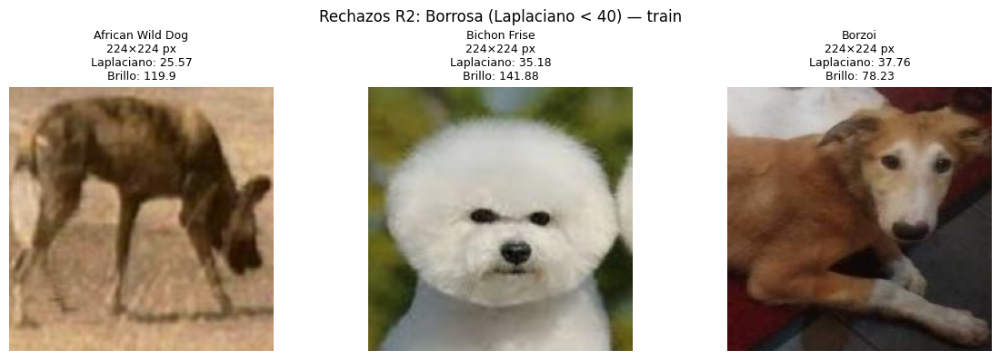

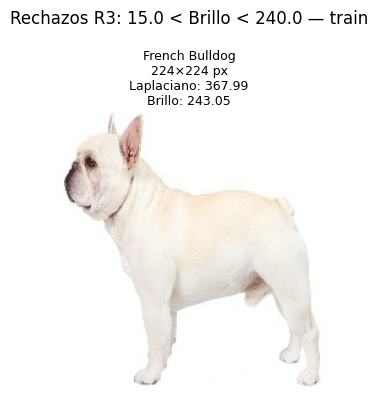

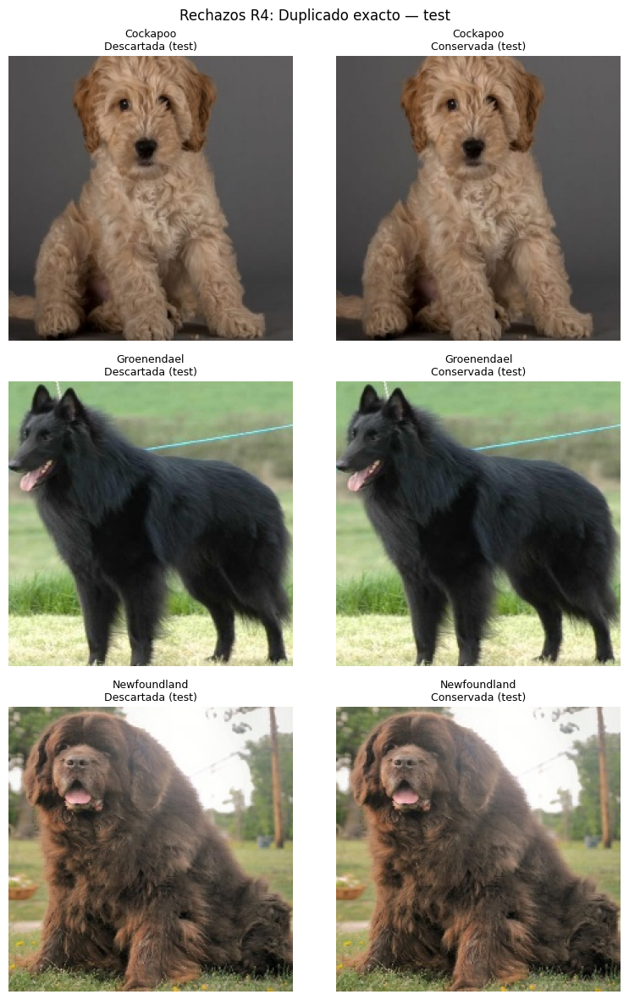

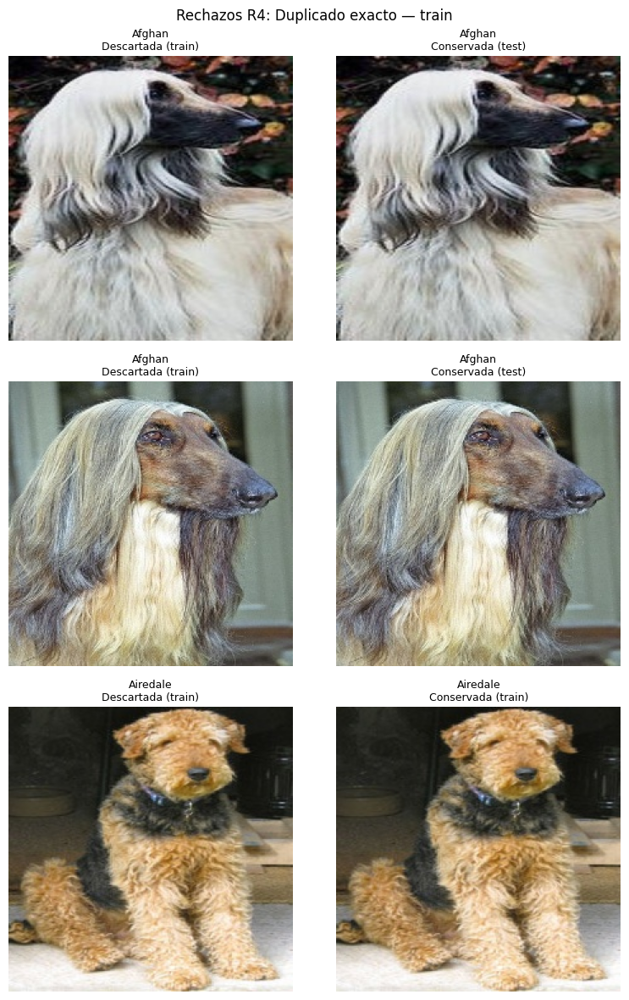

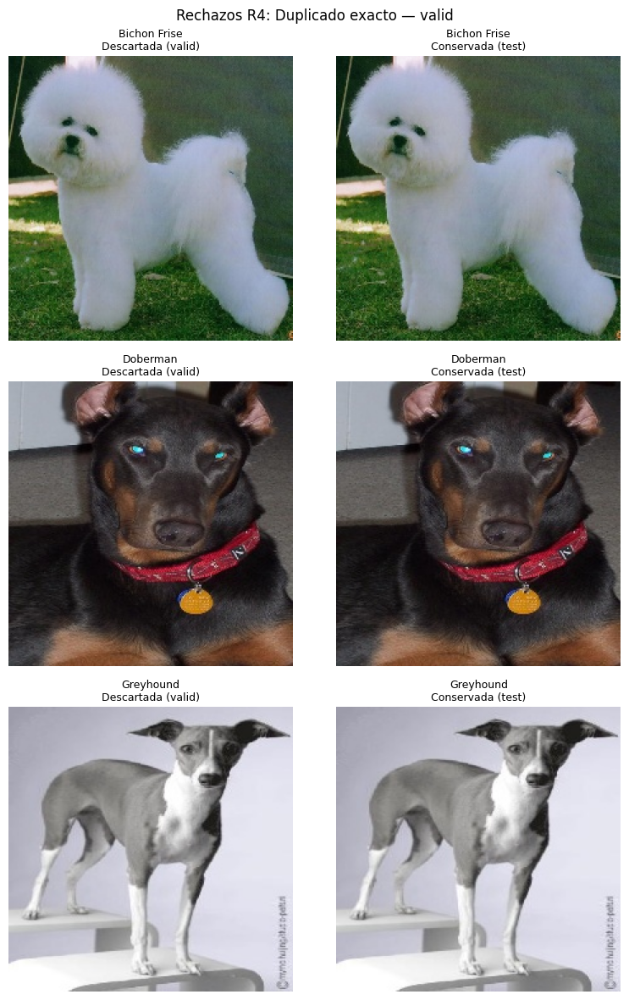

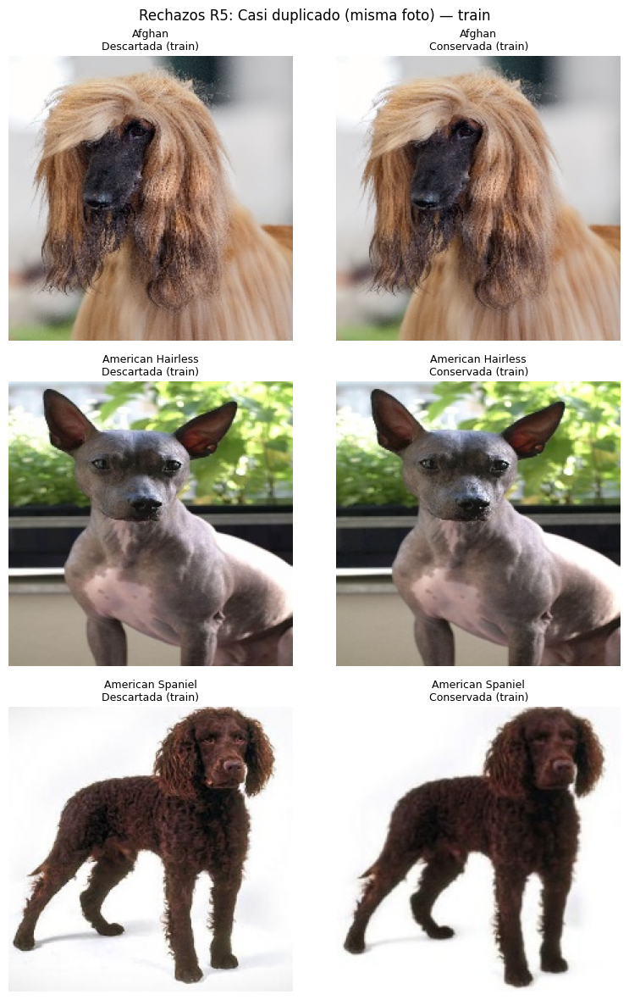

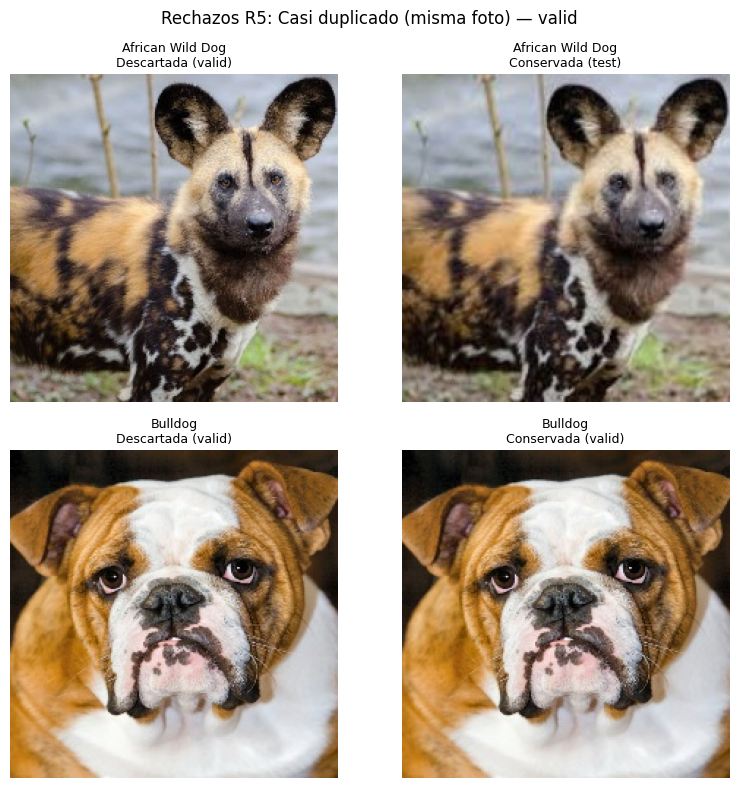

In [ ]:
# Ejemplos descartados por cada regla: validan visualmente que el umbral elegido tiene sentido.
def show_rejected_examples(
    quality: pl.DataFrame, dataset_dir: Path, rules: list[str] | None = None, n: int = 3
) -> None:
    """Muestra hasta `n` imágenes rechazadas por cada regla de calidad."""
    rejected = quality.filter(~pl.col("quality_rule").str.starts_with("Pasa"))
    if rejected.is_empty():
        print("No hay imágenes descartadas para mostrar.")
        return

    if rules is None:
        rules = rejected["quality_rule"].unique().sort().to_list()

    for rule in rules:
        rule_examples = rejected.filter(pl.col("quality_rule") == rule)
        if rule_examples.is_empty():
            continue

        for split in sorted(rule_examples["split"].unique().to_list()):
            examples = rule_examples.filter(pl.col("split") == split).head(n)

            # Los duplicados se muestran de a pares: descartada vs. la copia conservada.
            if rule.startswith(("R4:", "R5:")):
                fig, axes = plt.subplots(
                    examples.height, 2, figsize=(8, 4 * examples.height), squeeze=False
                )
                for ax_pair, row in zip(axes, examples.iter_rows(named=True)):
                    for ax, path, title in zip(
                        ax_pair,
                        [row["path"], row["duplicate_of"]],
                        [f"Descartada ({row['split']})", f"Conservada ({row['duplicate_of_split']})"],
                    ):
                        with Image.open(dataset_dir / path) as image:
                            ax.imshow(image.convert("RGB"))
                        ax.set_title(f"{row['breed']}\n{title}", fontsize=9)
                        ax.axis("off")
                fig.suptitle(f"Rechazos {rule} — {split}", fontsize=12)
                plt.tight_layout()
                plt.show()
                continue

            fig, axes = plt.subplots(
                1, examples.height, figsize=(4 * examples.height, 4), squeeze=False
            )
            for ax, row in zip(axes.flat, examples.iter_rows(named=True)):
                try:
                    with Image.open(dataset_dir / row["path"]) as image:
                        ax.imshow(image.convert("RGB"))
                except (UnidentifiedImageError, OSError):
                    # Placeholder para archivos corruptos: los mostramos en gris para no romper la grilla.
                    ax.imshow(np.full((64, 64, 3), 128, dtype=np.uint8))
                ax.set_title(
                    f"{row['breed']}\n{row['width']}×{row['height']} px"
                    + (f"\nLaplaciano: {row['laplacian_var']}" if row["laplacian_var"] is not None else "")
                    + (f"\nBrillo: {row['brightness']}" if row["brightness"] is not None else ""),
                    fontsize=9,
                )
                ax.axis("off")

            fig.suptitle(f"Rechazos {rule} — {split}", fontsize=12)
            plt.tight_layout()
            plt.show()


show_rejected_examples(quality, DATASET_DIR)

## 3.4 Conjunto independiente de evaluación

Es el conjunto que mide el comportamiento "en el mundo real" y se usa en las tres etapas.
Reglas:
- Imágenes **que no pertenecen al dataset** (internet o fotos propias).
- Mismas razas que las carpetas del dataset.
- Incluir imágenes "limpias" (un perro bien encuadrado) para Etapas 1 y 2, y escenas con
  varios perros / personas / objetos e imágenes **sin perros** para la Etapa 3.
- Meta: **al menos 100 imágenes** que cubran **20 razas o más**, incluyendo razas fáciles
  de confundir.
- Mismo criterio de calidad que los splits (legibilidad, blur < 40, brillo [15, 240]) y sin
  duplicados contra el dataset.

Las guardamos fuera del control de versiones en `data/dataset/independent/<raza>/`
(ya cubierto por `.gitignore`) y documentamos fuente y licencia de cada imagen en un
manifiesto CSV. Cada foto tiene una ruta y una fila por raza presente. Dos perros de la
misma raza comparten una sola fila con `multiple_dogs=true`. En una foto sin perros,
`breed` queda vacío y ambas marcas son falsas. La tabla por raza cuenta las fotos que
contienen esa raza, de modo que una escena mixta aparece en más de una categoría.

In [ ]:
# Creamos la carpeta del conjunto independiente y definimos el manifiesto con fuente/licencia.
INDEPENDENT_DIR = DATASET_DIR / "independent"
INDEPENDENT_MANIFEST = SPLITS_DIR / "independent_manifest.csv"

INDEPENDENT_DIR.mkdir(parents=True, exist_ok=True)
INDEPENDENT_MANIFEST.parent.mkdir(parents=True, exist_ok=True)

INDEPENDENT_SCHEMA = {
    "breed": pl.String,
    "path": pl.String,
    "filename": pl.String,
    "source": pl.String,
    "license": pl.String,
    "has_dog": pl.Boolean,
    "multiple_dogs": pl.Boolean,
}


def load_independent_manifest(manifest_path: Path) -> pl.DataFrame:
    """Carga el manifiesto independiente si existe; si no, devuelve uno vacío."""
    if manifest_path.exists():
        manifest = pl.read_csv(manifest_path, schema_overrides=INDEPENDENT_SCHEMA)
        missing = INDEPENDENT_SCHEMA.keys() - manifest.columns
        if missing:
            raise ValueError(f"Faltan columnas en el manifiesto: {', '.join(sorted(missing))}")
        return manifest.with_columns(pl.col("breed").str.strip_chars().replace("", None))
    return pl.DataFrame(schema=INDEPENDENT_SCHEMA)


def scan_independent(independent_dir: Path) -> pl.DataFrame:
    """Escanea las imágenes ya descargadas en el conjunto independiente."""
    records = []
    if independent_dir.is_dir():
        for image_path in sorted(independent_dir.rglob("*")):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_SUFFIXES:
                records.append(
                    {
                        "path": image_path.relative_to(independent_dir.parent).as_posix(),
                        "filename": image_path.name,
                    }
                )
    return pl.from_dicts(
        records,
        schema={"path": pl.String, "filename": pl.String},
    )


def audit_independent_set(manifest: pl.DataFrame, images: pl.DataFrame) -> pl.DataFrame:
    """Contrasta rutas con el disco y comprueba las etiquetas de cada foto."""
    issues = []
    files = set(images["path"])
    for path in sorted(files - set(manifest["path"])):
        issues.append((path, "Archivo sin fila en el manifiesto"))

    for photo in manifest.partition_by("path", maintain_order=True):
        path = photo["path"][0]
        if path not in files:
            issues.append((path, "La ruta del CSV no corresponde a una imagen en disco"))
        elif set(photo["filename"]) != {Path(path).name}:
            issues.append((path, "filename no coincide con el nombre en la ruta"))
        for field in ("source", "license"):
            if any(not (value or "").strip() for value in photo[field]):
                issues.append((path, f"Falta completar {field}"))

        breeds = photo["breed"]
        if breeds.is_duplicated().any():
            issues.append((path, "Etiqueta repetida para la misma foto"))
        if photo.height > 1 and breeds.null_count():
            issues.append((path, "Cada fila de una foto con varias etiquetas debe indicar una raza"))
        flags = photo.select("has_dog", "multiple_dogs").unique().rows()
        if len(flags) != 1 or None in flags[0]:
            issues.append((path, "Las marcas de la escena faltan o difieren entre filas"))
            continue
        has_dog, multiple_dogs = flags[0]
        if not has_dog and (multiple_dogs or breeds.drop_nulls().len() > 0):
            issues.append((path, "Una foto sin perros debe tener breed vacío y multiple_dogs=false"))
        elif not multiple_dogs and breeds.drop_nulls().n_unique() > 1:
            issues.append((path, "Varias razas en una foto requieren multiple_dogs=true"))

    return pl.DataFrame(issues, schema={"path": pl.String, "error": pl.String}, orient="row")


independent_images = scan_independent(INDEPENDENT_DIR)
manifest = load_independent_manifest(INDEPENDENT_MANIFEST)
audit_issues = audit_independent_set(manifest, independent_images)
print(
    f"Fotos en disco: {independent_images.height} | Rutas en el CSV: {manifest['path'].drop_nulls().n_unique()} "
    f"| Filas del manifiesto: {manifest.height}"
)
if not audit_issues.is_empty():
    mostrar(audit_issues)
elif not manifest.is_empty():
    print("Auditoría del manifiesto: sin observaciones.")
    resumen_independiente = (
        manifest.drop_nulls("breed").group_by("breed")
        .agg(pl.col("path").n_unique().alias("images"))
        .sort("images", descending=True)
    )
    mostrar(resumen_independiente)

Fotos en disco: 10 | Rutas en el CSV: 10 | Filas del manifiesto: 11
Auditoría del manifiesto: sin observaciones.


raza,imágenes
str,u32
"""Poodle""",2
"""Labrador""",2
"""Cockapoo""",2
"""Labradoodle""",2
"""Golden Retriever""",1
"""Beagle""",1


**Recolección del conjunto independiente**
 El manifiesto `splits/independent_manifest.csv` se completa a medida que el equipo descarga fotos propias o de
internet. Para cada imagen se registra `breed`, `path`, `source` (URL o "foto propia") y
`license` (por ejemplo CC BY 4.0, CC BY-SA 4.0, o "foto propia"). Las imágenes sin perro (gatos,
escenas urbanas) van en una carpeta especial `independent/sin_perro/` con `has_dog=False` para
probar falsos positivos del detector en la Etapa 3.


## 3.5 Preprocesamiento

El preprocesamiento vive como módulo en **`src/lib/image_pipeline.py`**

Pipeline de preprocesamiento:

- **Orden de canales:** la app y OpenCV entregan **BGR**; PIL y torchvision trabajan en **RGB**.
  `bgr_to_rgb` es el único lugar donde se hace esa conversión.
- **Encuadre: letterbox** (escala preservando aspecto + relleno reflejo hasta 224×224). Se
  prefiere al resize directo (deforma) y al center-crop (corta patas y orejas). Como el dataset
  ya es cuadrado, en `train`/`valid`/`test` el letterbox es la identidad; en la Etapa 3 actúa
  sobre los recortes de YOLO, que no son cuadrados.
- **Normalización:** media y desvío de **ImageNet**, que es lo que esperan los modelos
  preentrenados. La CNN propia usa las mismas para poder comparar y reutilizar el pipeline.
- **Escala:** píxeles a `[0, 1]` y después `(x - media) / desvío`, y `HWC → CHW`.

En las celdas de abajo se aplica el pipeline a 4 imágenes del dataset: el tensor desnormalizado
se ve **igual** que el original porque en 224×224 la geometría es no-op; lo que cambió son los
valores (BGR→RGB, [0,1], media/desvío) y el orden de ejes. En las fotos independientes
rectangulares se puede observar el relleno que agrega el letterbox.

In [29]:
# El pipeline de imagen se importa del módulo compartido con la app.
from lib.image_pipeline import (
    IMAGE_SIZE,
    bgr_to_rgb,
    denormalize,
    expand_box,
    letterbox,
    preprocess,
    to_batch,
)

In [ ]:
# Verificación del pipeline: formas, rango y que BGR→RGB coincida con PIL.

sample_path = accepted.sample(n=1, seed=SEED)["path"][0]
sample_bgr = cv2.imread(str(DATASET_DIR / sample_path))
sample_pre = preprocess(sample_bgr)

print(f"Imagen de ejemplo: {sample_path}")
print(f"original:     {sample_bgr.shape} {sample_bgr.dtype} (BGR uint8)")
print(f"preprocesada: {sample_pre.shape} {sample_pre.dtype} (CHW float32, ImageNet)")
print(f"batch:        {to_batch(sample_pre).shape}")
print(f"rango: [{sample_pre.min():.2f}, {sample_pre.max():.2f}]")
print(f"media por canal de esta imagen (el dataset da ~0): {np.round(sample_pre.mean(axis=(1, 2)), 3)}")

with Image.open(DATASET_DIR / sample_path) as image:
    rgb_pil = np.asarray(image.convert("RGB"))
print(f"BGR→RGB coincide con PIL: {np.array_equal(bgr_to_rgb(sample_bgr), rgb_pil)}")

Imagen de ejemplo: train/Shih-Tzu/112.jpg
original:     (224, 224, 3) uint8 (BGR uint8)
preprocesada: (3, 224, 224) float32 (CHW float32, ImageNet)
batch:        (1, 3, 224, 224)
rango: [-2.12, 2.64]
media por canal de esta imagen (el dataset da ~0): [-0.21   0.206  0.497]
BGR→RGB coincide con PIL: True


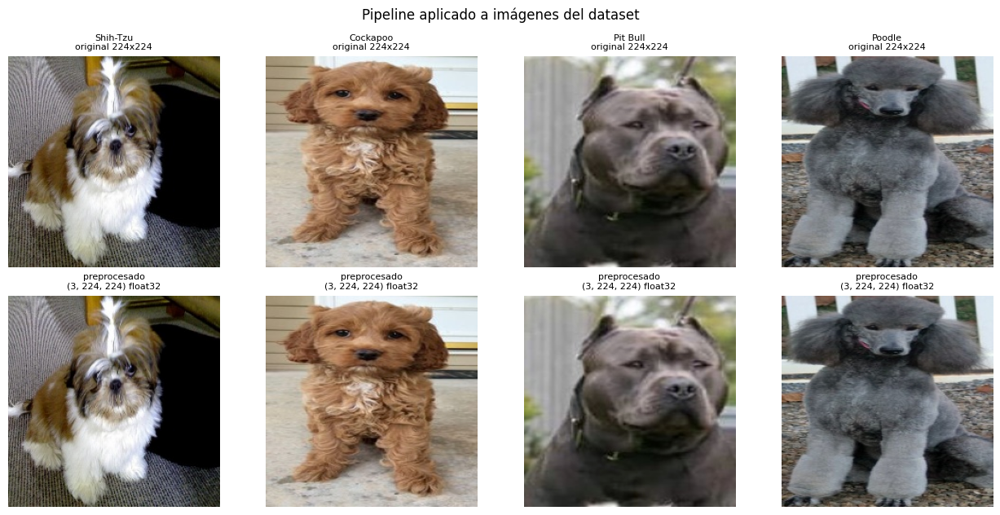

In [ ]:
# El pipeline sobre imágenes reales: original vs. preprocesado (desnormalizado).
def show_pipeline_examples(samples: pl.DataFrame, dataset_dir: Path) -> None:
    """Muestra original vs. preprocesado para cada imagen de `samples` (una columna por imagen)."""
    figure, axes = plt.subplots(2, samples.height, figsize=(3.2 * samples.height, 6.4), squeeze=False)
    for column, row in enumerate(samples.iter_rows(named=True)):
        image = cv2.imread(str(dataset_dir / row["path"]))
        if image is None:
            continue
        tensor = preprocess(image)
        axes[0, column].imshow(bgr_to_rgb(image))
        axes[0, column].set_title(
            f"{row['breed']}\noriginal {image.shape[1]}x{image.shape[0]}", fontsize=8
        )
        axes[1, column].imshow(denormalize(tensor))
        axes[1, column].set_title(f"preprocesado\n{tensor.shape} float32", fontsize=8)
    for ax in axes.flat:
        ax.axis("off")
    figure.suptitle("Pipeline aplicado a imágenes del dataset", fontsize=12)
    plt.tight_layout()
    plt.show()


kaggle_samples = accepted.sample(n=4, seed=SEED).select(["breed", "path"])
show_pipeline_examples(kaggle_samples, DATASET_DIR)

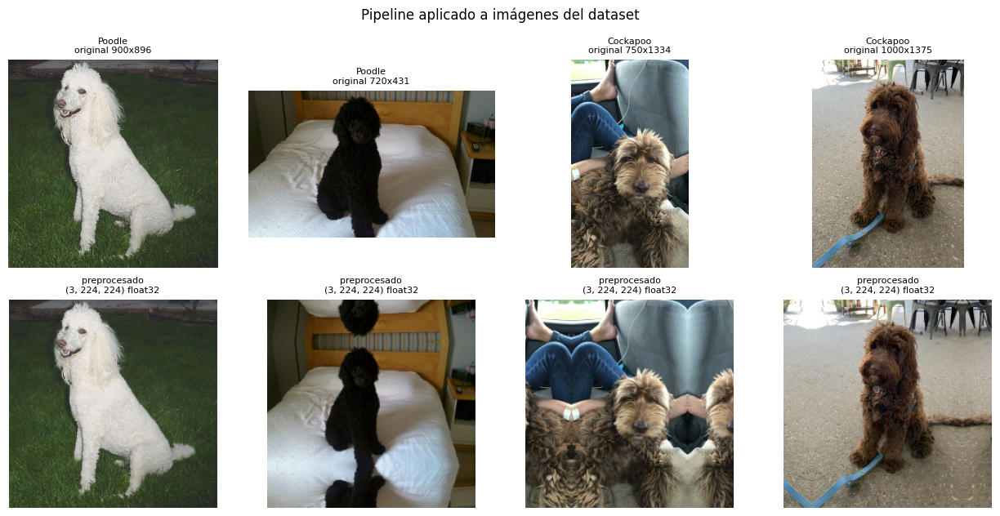

In [ ]:
# Una columna por foto, con las razas del manifiesto aunque comparta carpeta con otras escenas.
if audit_issues.is_empty() and not manifest.is_empty():
    unlabelled = (
        pl.when(pl.col("has_dog")).then(pl.lit("Raza sin informar")).otherwise(pl.lit("Sin perro"))
    )
    independent_preview = manifest.group_by("path", maintain_order=True).agg(
        pl.col("breed").fill_null(unlabelled).str.join(" / ").alias("breed")
    )
    show_pipeline_examples(independent_preview.head(4), DATASET_DIR)

## 3.6 Data augmentation

El pipeline está en **`src/lib/augmentation.py`** y se aplica **solo sobre `train`**: validación,
test y el conjunto independiente se evalúan con el preprocesamiento determinista.

| Transformación | Rango | Por qué |
|---|---|---|
| Flip horizontal | p = 0.5 | el perro puede mirar a cualquier lado |
| Affine (escala 0.9–1.1, traslación ±5 %, rotación ±15°) | p = 0.5 | encuadre y pose variables; ±15° no cambia la raza aparente |
| Random resized crop | 70–100 % del área | simula recortes más cerrados (los de YOLO) |
| Brillo / contraste | ±20 % | interiores, exteriores y exposiciones distintas |
| Blur (gaussiano o de movimiento) | p = 0.2 | fotos movidas o desenfocadas |
| Ruido gaussiano | σ = 0.02–0.08 | compresión y sensores de baja calidad |

**Afuera:** flip vertical, rotaciones de 90° y cambios de color/hue fuertes: no ocurren en la
realidad y cambian la raza aparente.

In [33]:
# Augmentation: solo train.
from lib.augmentation import build_train_transform

transform = build_train_transform(image_size=IMAGE_SIZE, seed=SEED)
augmented = transform(image=sample_bgr)["image"]
print(f"una imagen aumentada: {augmented.shape} {augmented.dtype} (BGR uint8)")

una imagen aumentada: (224, 224, 3) uint8 (BGR uint8)


## 3.7 Partición de datos

Los splits se redefinen sobre el dataset de kaggle ya filtrado: **70 % train / 15 % valid / 15 % test**,
**balanceado por clase**. Para cada raza se mezcla y se asignan 15% a valid,
15% a test y el resto a train.

Sobre el conjunto de train resultante, se aplica el pipeline de augmentation offline:
Se generan copias de las razas con menos
imágenes hasta que todas tengan la cantidad de la más numerosa, se escriben en
`data/dataset/augmented/` (no versionado) y se registran en `splits/train_augmented.csv`.



In [34]:
# Reparto 70/15/15 por clase, reproducible y balanceado.
VALID_FRACTION = 0.15
TEST_FRACTION = 0.15


def split_by_class(
    df: pl.DataFrame,
    valid_fraction: float = VALID_FRACTION,
    test_fraction: float = TEST_FRACTION,
    seed: int = SEED,
) -> pl.DataFrame:
    """Asigna train/valid/test por clase respetando las fracciones (mínimo 1 por split).

    Cada raza se mezcla con una semilla propia (`seed + índice`) para que el reparto sea
    reproducible e independiente del orden de las filas.
    """
    parts = []
    for index, breed in enumerate(sorted(df["breed"].unique().to_list())):
        group = df.filter(pl.col("breed") == breed)
        shuffled = group.sample(n=group.height, shuffle=True, seed=seed + index)
        n = shuffled.height
        n_valid = max(1, int(round(valid_fraction * n)))
        n_test = max(1, int(round(test_fraction * n)))
        n_train = n - n_valid - n_test
        if n_train < 1:  # clases muy chicas: se recortan valid/test
            n_train = 1
            n_valid = max(1, (n - 1) // 2)
            n_test = n - 1 - n_valid
        parts.append(
            shuffled.with_row_index("pos")
            .with_columns(
                pl.when(pl.col("pos") < n_valid)
                .then(pl.lit("valid"))
                .when(pl.col("pos") < n_valid + n_test)
                .then(pl.lit("test"))
                .otherwise(pl.lit("train"))
                .alias("split")
            )
            .drop("pos")
        )
    return pl.concat(parts).sort(["split", "breed", "path"])

In [ ]:
# Splits finales sobre el conjunto filtrado.
final = split_by_class(accepted.select(["breed", "path", "filename"])).select(
    ["split", "breed", "path", "filename"]
)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

for split in ("train", "valid", "test"):
    subset = final.filter(pl.col("split") == split)
    subset.write_csv(SPLITS_DIR / f"{split}.csv")
    print(f"{split}.csv: {subset.height} imágenes")

final.write_csv(SPLITS_DIR / "all.csv")

discarded = (
    quality.filter(pl.col("quality_rule") != "Pasa reglas visuales")
    .select(["split", "breed", "path", "quality_rule", "duplicate_of", "duplicate_of_split"])
    .rename({"split": "split_original"})
    .sort(["split_original", "breed", "path"])
)
discarded.write_csv(SPLITS_DIR / "descartadas.csv")
print(f"descartadas.csv: {discarded.height} imágenes (columna split_original)")

per_breed = final.group_by(["split", "breed"]).len()
resumen_splits = (
    per_breed.group_by("split")
    .agg(
        pl.len().alias("razas"),
        pl.col("len").sum().alias("imágenes"),
        pl.col("len").min().alias("mín por raza"),
        pl.col("len").max().alias("máx por raza"),
    )
    .sort("split")
)
mostrar(resumen_splits)
print(
    "proporción: "
    f"{ {row['split']: round(row['imágenes'] / final.height, 3) for row in resumen_splits.iter_rows(named=True)} }"
)

train.csv: 6427 imágenes
valid.csv: 1379 imágenes
test.csv: 1379 imágenes
descartadas.csv: 161 imágenes (columna split_original)


partición,razas,imágenes,mín por raza,máx por raza
str,u32,u32,u32,u32
"""test""",70,1379,13,32
"""train""",70,6427,58,151
"""valid""",70,1379,13,32


proporción: {'test': 0.15, 'train': 0.7, 'valid': 0.15}


In [ ]:
# Equilibramos train con augmentation: cada raza llega a la cantidad de la más numerosa.
train_split = final.filter(pl.col("split") == "train")
train_counts = train_split.group_by("breed").len().rename({"len": "images"})
TRAIN_TARGET = int(train_counts["images"].max())

AUGMENT_DIR = DATASET_DIR / "augmented" / "train"
if AUGMENT_DIR.exists():
    shutil.rmtree(AUGMENT_DIR)

AUGMENTED_SCHEMA = {
    "split": pl.String,
    "breed": pl.String,
    "path": pl.String,
    "filename": pl.String,
    "origin": pl.String,
}


def augment_to_balance(
    train: pl.DataFrame,
    target: int,
    transform: A.Compose,
    dataset_dir: Path,
    output_dir: Path,
) -> pl.DataFrame:
    """Genera copias augmentadas por clase hasta llegar a `target` imágenes por raza.

    Recorre las imágenes de cada clase en round-robin, así las copias se reparten entre todas.
    Las clases que ya tienen `target` no se tocan. El nombre de archivo usa un contador global
    (`00001_aug.jpg`); el mapeo a la imagen original queda en la columna `origin`.
    """
    records = []
    counter = 0
    for breed in sorted(train["breed"].unique().to_list()):
        breed_rows = train.filter(pl.col("breed") == breed).sort("path").to_dicts()
        needed = target - len(breed_rows)
        if needed <= 0:
            continue
        for index in range(needed):
            source = breed_rows[index % len(breed_rows)]
            image = cv2.imread(str(dataset_dir / source["path"]))
            if image is None:
                continue
            augmented = transform(image=image)["image"]
            dest_dir = output_dir / breed
            dest_dir.mkdir(parents=True, exist_ok=True)
            counter += 1
            dest = dest_dir / f"{counter:05d}_aug.jpg"
            cv2.imwrite(str(dest), augmented, [cv2.IMWRITE_JPEG_QUALITY, 92])
            records.append(
                {
                    "split": "train",
                    "breed": breed,
                    "path": dest.relative_to(dataset_dir).as_posix(),
                    "filename": dest.name,
                    "origin": source["path"],
                }
            )
    return pl.from_dicts(records, schema=AUGMENTED_SCHEMA)


print(
    f"train: {train_split.height} imágenes | target por raza: {TRAIN_TARGET} | "
    f"razas a aumentar: {train_counts.filter(pl.col('images') < TRAIN_TARGET).height}"
)

train_augmented = augment_to_balance(
    train_split, TRAIN_TARGET, transform, DATASET_DIR, AUGMENT_DIR
)

columns = ["split", "breed", "path", "filename", "origin"]
train_for_training = pl.concat(
    [
        train_split.with_columns(pl.lit("original").alias("origin")).select(columns),
        train_augmented.select(columns),
    ]
).sort(["breed", "path"])
train_for_training.write_csv(SPLITS_DIR / "train_augmented.csv")

balance = train_for_training.group_by("breed").len()
print(f"aumentadas: {train_augmented.height} imágenes")
print(f"train_augmented.csv: {train_for_training.height} filas")
print(f"por raza después: {balance['len'].min()}–{balance['len'].max()} (target {TRAIN_TARGET})")
assert train_augmented["path"].n_unique() == train_augmented.height, "rutas aumentadas repetidas"
assert train_for_training["path"].n_unique() == train_for_training.height, "rutas repetidas"

train: 6427 imágenes | target por raza: 151 | razas a aumentar: 69
aumentadas: 4143 imágenes
train_augmented.csv: 10570 filas
por raza después: 151–151 (target 151)


In [ ]:
# Distribución por clase antes y después: el augmentation empareja todas las razas.
before = train_split.group_by("breed").len().rename({"len": "antes"})
after = train_for_training.group_by("breed").len().rename({"len": "después"})
counts = (
    before.join(after, on="breed")
    .unpivot(index="breed", variable_name="momento", value_name="imágenes")
)

balance_chart = (
    alt.Chart(inline(counts))
    .mark_bar()
    .encode(
        x=alt.X("breed:N", title=None, axis=alt.Axis(labelAngle=-90, labelFontSize=7)),
        xOffset="momento:N",
        y=alt.Y("imágenes:Q", title="Imágenes en train"),
        color=alt.Color(
            "momento:N",
            title=None,
            scale=alt.Scale(range=[COLORS["gray"], COLORS["primary"]]),
        ),
        tooltip=["breed:N", "momento:N", "imágenes:Q"],
    )
    .properties(width=1100, height=320, title="Train por clase: antes y después de equilibrar")
)
display(balance_chart)

alt.Chart(...)

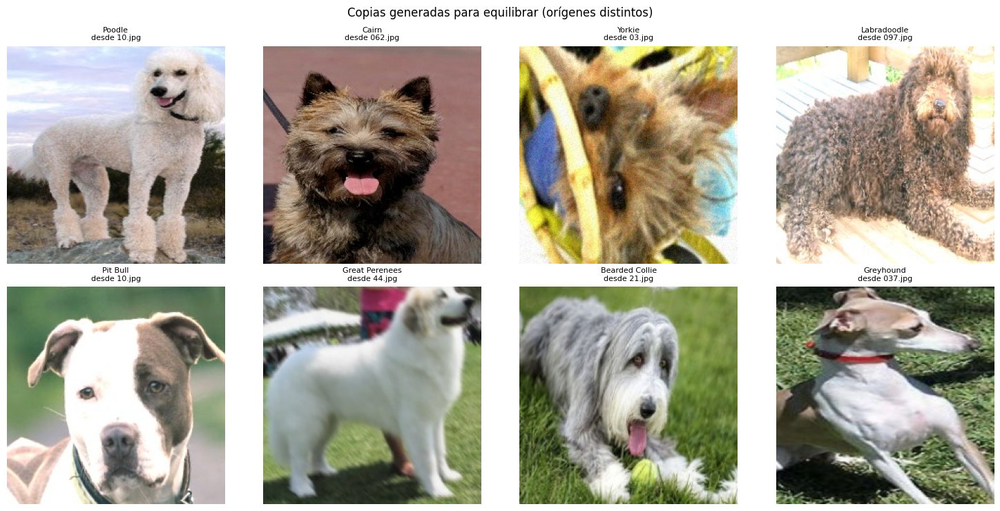

data\dataset\augmented\train → 77 MB


In [38]:
# Las copias generadas vienen de imágenes distintas (no son N versiones de la misma foto).
sample_aug = train_augmented.sample(n=8, seed=SEED)
figure, axes = plt.subplots(2, 4, figsize=(15, 7.5), squeeze=False)
for ax, row in zip(axes.flat, sample_aug.iter_rows(named=True)):
    with Image.open(DATASET_DIR / row["path"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{row['breed']}\ndesde {Path(row['origin']).name}", fontsize=8)
    ax.axis("off")
figure.suptitle("Copias generadas para equilibrar (orígenes distintos)", fontsize=12)
plt.tight_layout()
plt.show()

size_mb = sum(path.stat().st_size for path in AUGMENT_DIR.rglob("*.jpg")) / 1e6
print(f"{AUGMENT_DIR.relative_to(ROOT)} → {size_mb:.0f} MB")

In [ ]:
# Verificación de fuga: cada imagen una sola vez y sin duplicados entre particiones.
repetidas = final.group_by("path").len().filter(pl.col("len") > 1)
print(f"Rutas repetidas entre splits: {repetidas.height}")

exact_check = mark_duplicates(final.select(["path", "split", "breed"]), DATASET_DIR)
near_check = mark_near_duplicates(final.select(["path", "split", "breed"]), DATASET_DIR)
print(f"Archivos idénticos entre splits: {exact_check.filter(pl.col('is_duplicate')).height}")
print(f"Casi-duplicados entre splits: {near_check.filter(pl.col('is_near_duplicate')).height}")

Rutas repetidas entre splits: 0
Archivos idénticos entre splits: 0
Casi-duplicados entre splits: 0


## 3.8 Licencias y uso de imágenes

- **Dataset:** *70 Dog Breeds Image Dataset* (Kaggle, `gpiosenka`). La licencia publicada es
  **CC0 (dominio público)**; conviene verificarla en la página actual del dataset antes de
  cualquier uso fuera de lo académico, porque los derechos de cada imagen individual pueden
  tener otra procedencia.
- **Conjunto independiente:** cada imagen tiene su fuente y licencia en
  `splits/independent_manifest.csv` (CC BY, CC BY-SA, CC0 o foto propia).
- **Personas identificables:** se evitan en el conjunto independiente. Si una escena de la
  Etapa 3 las incluye, no se publica.
- **Uso:** exclusivamente académico, sin fines comerciales.

In [ ]:
# Tabla resumen final del dataset curado.
print("Dataset final")
mostrar(resumen_splits)

print("\nDescartes por regla")
mostrar(
    discarded.group_by("quality_rule").len().rename({"len": "images"}).sort("quality_rule")
)

print("\nConjunto independiente")
print(
    f"{independent_images.height} fotos en disco; {audit_issues.height} observaciones del manifiesto "
    f"(meta ≥ 100, ≥ 20 razas)"
)

print(f"\nTotal dataset curado: {final.height} imágenes originales de {final['breed'].n_unique()} razas")
print(
    f"Train para entrenar (originales + aumentadas): {train_for_training.height} imágenes "
    f"({train_split.height} originales + {train_augmented.height} aumentadas)"
)
print("Galería de la Etapa 1: train_augmented.csv (originales + aumentadas).")

Dataset final


partición,razas,imágenes,mín por raza,máx por raza
str,u32,u32,u32,u32
"""test""",70,1379,13,32
"""train""",70,6427,58,151
"""valid""",70,1379,13,32



Descartes por regla


regla,imágenes
str,u32
"""R2: Borrosa (Laplaciano < 40)""",9
"""R3: 15.0 < Brillo < 240.0""",1
"""R4: Duplicado exacto""",119
"""R5: Casi duplicado (misma foto…",32



Conjunto independiente
10 fotos en disco; 0 observaciones del manifiesto (meta ≥ 100, ≥ 20 razas)

Total dataset curado: 9185 imágenes originales de 70 razas
Train para entrenar (originales + aumentadas): 10570 imágenes (6427 originales + 4143 aumentadas)
Galería de la Etapa 1: train_augmented.csv (originales + aumentadas).
